In [3]:
import pandas as pd
import os

file_path = r"C:\Users\lenovo\OneDrive\Desktop\data science\Movie-Review-Naive-Bayes\IMDB-Dataset.csv"

print(os.path.exists(file_path))
df = pd.read_csv(file_path)

df.head()

True


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [7]:
# Import visualization libraries and inspect the dataset

# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from collections import Counter
from IPython.display import display

# Set a consistent professional plotting style
sns.set_theme(style="whitegrid", context="notebook")

# Check dataset dimensions and column names
print("Dataset Shape:", df.shape)
print("\nColumn Names:", df.columns.tolist())

# Display data types and non-null counts
print("\nDataset Information:")
df.info()

# Display statistical summaries
print("\nDataset Summary:")
display(df.describe(include="all"))

# Preview random reviews
print("\nRandom Sample Reviews:")
display(df.sample(min(5, len(df)), random_state=42))


Dataset Shape: (50000, 2)

Column Names: ['review', 'sentiment']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
dtypes: str(2)
memory usage: 63.6 MB

Dataset Summary:


,review,sentiment
count,50000,50000
unique,49582,2
top,Loved today's show!!! It was a variety and not...,positive
freq,5,25000



Random Sample Reviews:


,review,sentiment
33553,I really liked this Summerslam due to the look...,positive
9427,Not many television shows appeal to quite as m...,positive
199,The film quickly gets to a major chase scene w...,negative
12447,Jane Austen would definitely approve of this o...,positive
39489,Expectations were somewhat high for me when I ...,negative


In [8]:
#Step 2 — Data quality analysis

# Missing values
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage (%)": (df.isnull().mean() * 100).round(2)
})

print("Missing Value Analysis:")
display(missing_summary)

# Duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Empty or whitespace-only reviews
empty_reviews = (
    df["review"].fillna("").astype(str).str.strip().eq("").sum()
)
print("Empty reviews:", empty_reviews)

# Missing sentiment labels
print("Missing sentiment labels:", df["sentiment"].isnull().sum())

# Unique sentiment labels
print("\nUnique sentiment labels:")
print(df["sentiment"].value_counts(dropna=False))


Missing Value Analysis:


,Missing Count,Missing Percentage (%)
review,0,0.0
sentiment,0,0.0


Duplicate rows: 418
Empty reviews: 0
Missing sentiment labels: 0

Unique sentiment labels:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64


Sentiment Distribution:


,Review Count,Percentage (%)
sentiment,,
positive,25000,50.0
negative,25000,50.0


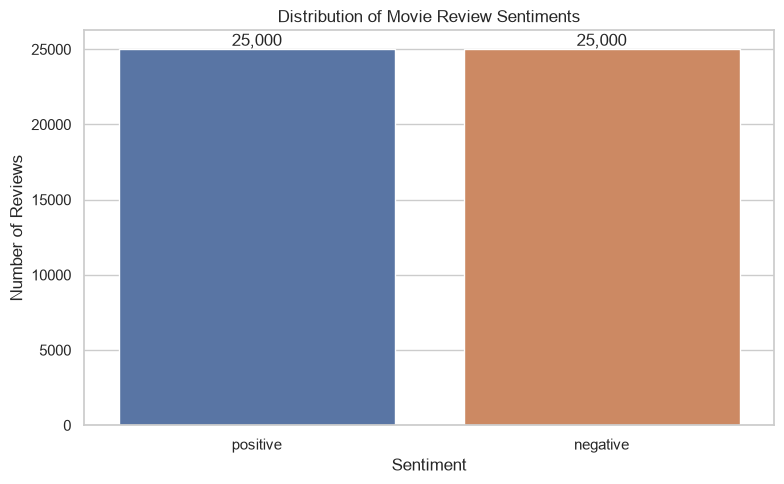

In [9]:
#Step 3 — Sentiment distribution

# Count each sentiment
sentiment_counts = df["sentiment"].value_counts()

# Calculate percentages
sentiment_percentages = (
    df["sentiment"].value_counts(normalize=True) * 100
).round(2)

sentiment_summary = pd.DataFrame({
    "Review Count": sentiment_counts,
    "Percentage (%)": sentiment_percentages
})

print("Sentiment Distribution:")
display(sentiment_summary)

# Visualize sentiment counts
plt.figure(figsize=(8, 5))
ax = sns.countplot(
    data=df,
    x="sentiment",
    hue="sentiment",
    order=sentiment_counts.index,
    legend=False
)

plt.title("Distribution of Movie Review Sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

for bar in ax.patches:
    ax.annotate(
        f"{int(bar.get_height()):,}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


Review Length Statistics:


review_length                                                 \
                  count     mean      std   min    25%    50%      75%   
sentiment                                                                
negative        25000.0  1294.06   945.89  32.0  706.0  973.0  1567.25   
positive        25000.0  1324.80  1031.49  65.0  691.0  968.0  1614.00   

                   word_count          ...                sentence_count  \
               max      count    mean  ...    75%     max          count   
sentiment                              ...                                 
negative    8969.0    25000.0  229.46  ...  278.0  1522.0        25000.0   
positive   13704.0    25000.0  232.85  ...  284.0  2470.0        25000.0   

                                                     
            mean   std  min  25%   50%   75%    max  
sentiment                                            
negative   13.52  9.51  0.0  8.0  11.0  16.0  145.0  
positive   12.79  9.36  0.0  7.0  10.0  16.0  282.0  

[2 rows x 24 columns]

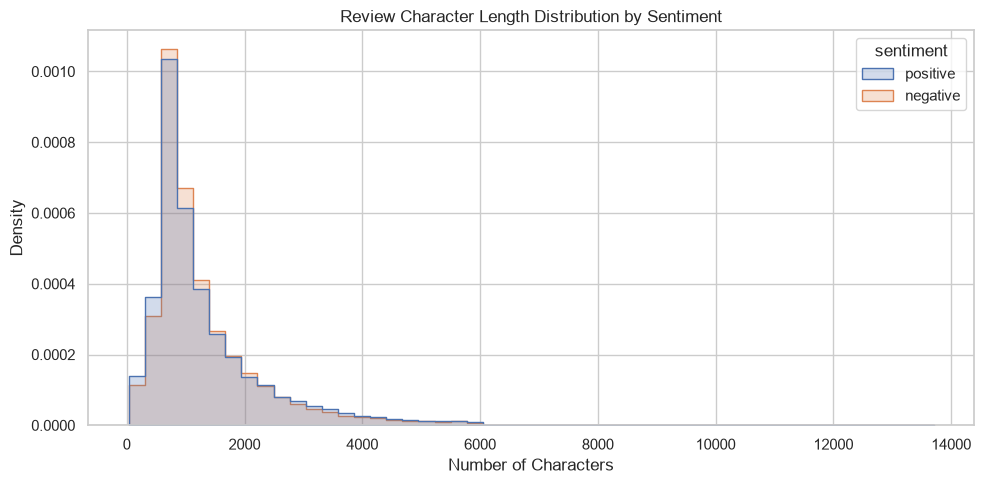

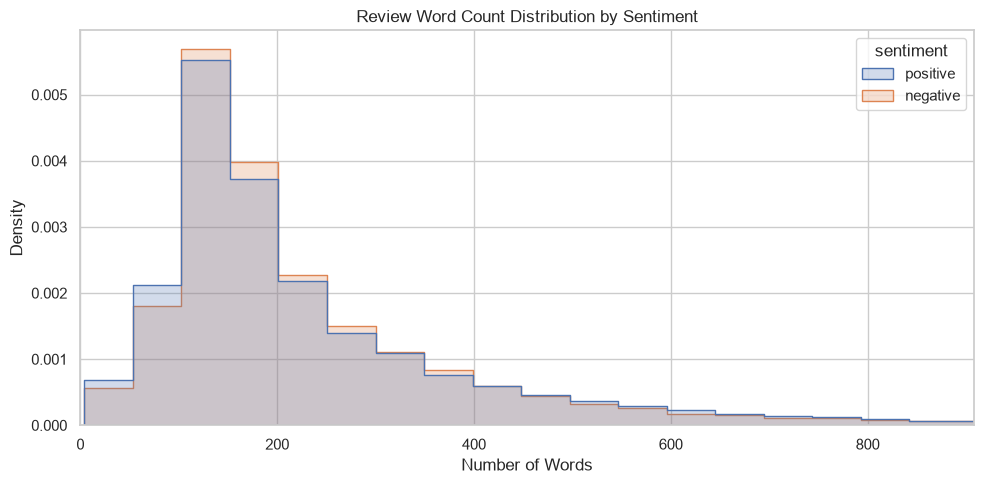

In [10]:
#Step 4 — Review length analysis
#We should investigate how long reviews are and whether positive and negative reviews differ in length.

# Create text-based features for EDA
eda_df = df.copy()

# Count characters in each review
eda_df["review_length"] = (
    eda_df["review"].fillna("").astype(str).str.len()
)

# Count words in each review
eda_df["word_count"] = (
    eda_df["review"].fillna("").astype(str)
    .str.split()
    .str.len()
)

# Count sentences approximately
eda_df["sentence_count"] = (
    eda_df["review"].fillna("").astype(str)
    .str.count(r"[.!?]+")
)

# Summary statistics
print("Review Length Statistics:")
display(
    eda_df.groupby("sentiment")[
        ["review_length", "word_count", "sentence_count"]
    ].describe().round(2)
)

# Character length distribution
plt.figure(figsize=(10, 5))
sns.histplot(
    data=eda_df,
    x="review_length",
    hue="sentiment",
    bins=50,
    element="step",
    stat="density",
    common_norm=False
)
plt.title("Review Character Length Distribution by Sentiment")
plt.xlabel("Number of Characters")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

# Word count distribution, limiting the x-axis for readability
plt.figure(figsize=(10, 5))
sns.histplot(
    data=eda_df,
    x="word_count",
    hue="sentiment",
    bins=50,
    element="step",
    stat="density",
    common_norm=False
)
plt.xlim(0, eda_df["word_count"].quantile(0.99))
plt.title("Review Word Count Distribution by Sentiment")
plt.xlabel("Number of Words")
plt.ylabel("Density")
plt.tight_layout()
plt.show()


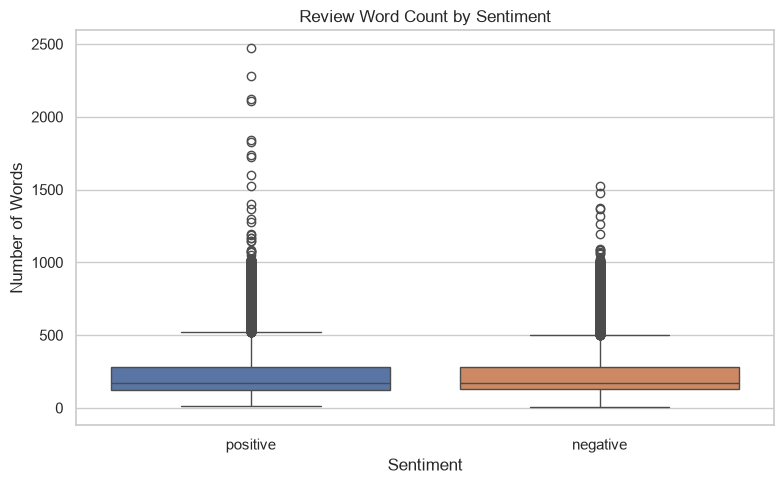

Average Review Length by Sentiment:


,review_length,word_count,sentence_count
sentiment,,,
negative,1294.06,229.46,13.52
positive,1324.80,232.85,12.79


In [11]:
#Step 5 — Compare review lengths by sentiment

# Compare word counts across the sentiment classes
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=eda_df,
    x="sentiment",
    y="word_count",
    hue="sentiment",
    legend=False
)
plt.title("Review Word Count by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of Words")
plt.tight_layout()
plt.show()

# Compare numerical review features
print("Average Review Length by Sentiment:")
display(
    eda_df.groupby("sentiment")[
        ["review_length", "word_count", "sentence_count"]
    ].mean().round(2)
)


In [12]:
#Step 6 — Inspect raw reviews

# Display positive and negative examples
for label in ["positive", "negative"]:
    examples = df.loc[
        df["sentiment"].astype(str).str.lower() == label,
        "review"
    ].dropna().head(3)

    print(f"\n{'=' * 20} {label.upper()} EXAMPLES {'=' * 20}")

    for number, review in enumerate(examples, start=1):
        print(f"\nExample {number}:\n")
        print(review[:700])



==================== POSITIVE EXAMPLES ====================

Example 1:

One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face

Example 2:

A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece. <br /><br 

In [13]:
#Step 7 — Analyze HTML tags and punctuation

# Count reviews containing HTML tags
html_tag_count = (
    df["review"].fillna("").astype(str)
    .str.contains(r"<[^>]+>", regex=True)
    .sum()
)

# Count reviews containing URLs
url_count = (
    df["review"].fillna("").astype(str)
    .str.contains(r"https?://|www\.", case=False, regex=True)
    .sum()
)

# Count reviews containing digits
digit_count = (
    df["review"].fillna("").astype(str)
    .str.contains(r"\d", regex=True)
    .sum()
)

# Count reviews containing uppercase letters
uppercase_count = (
    df["review"].fillna("").astype(str)
    .str.contains(r"[A-Z]", regex=True)
    .sum()
)

text_characteristics = pd.DataFrame({
    "Characteristic": [
        "Reviews containing HTML tags",
        "Reviews containing URLs",
        "Reviews containing digits",
        "Reviews containing uppercase letters"
    ],
    "Review Count": [
        html_tag_count,
        url_count,
        digit_count,
        uppercase_count
    ]
})

print("Text Characteristics:")
display(text_characteristics)


Text Characteristics:


,Characteristic,Review Count
0,Reviews containing HTML tags,29202
1,Reviews containing URLs,202
2,Reviews containing digits,28005
3,Reviews containing uppercase letters,49780


In [15]:
#Step 8 — Most frequent words in the original reviews

# Combine a sample of reviews to keep the exploratory step manageable
sample_size = min(10000, len(df))

sample_df = df.sample(sample_size, random_state=42)

positive_text = " ".join(
    sample_df.loc[
        sample_df["sentiment"].astype(str).str.lower() == "positive",
        "review"
    ].dropna().astype(str)
).lower()

negative_text = " ".join(
    sample_df.loc[
        sample_df["sentiment"].astype(str).str.lower() == "negative",
        "review"
    ].dropna().astype(str)
).lower()

# Extract alphabetic tokens of at least 2 characters
positive_words = re.findall(r"\b[a-z]{2,}\b", positive_text)
negative_words = re.findall(r"\b[a-z]{2,}\b", negative_text)

# Display the 20 most frequent words
print("Top 20 Words in Positive Reviews:")
display(pd.DataFrame(
    Counter(positive_words).most_common(20),
    columns=["Word", "Frequency"]
))

print("\nTop 20 Words in Negative Reviews:")
display(pd.DataFrame(
    Counter(negative_words).most_common(20),
    columns=["Word", "Frequency"]
))


Top 20 Words in Positive Reviews:


,Word,Frequency
0,the,68101
1,and,35713
2,of,30703
3,to,26333
4,is,22621
5,in,20198
6,br,19350
7,it,19213
8,this,13981
9,that,13755



Top 20 Words in Negative Reviews:


,Word,Frequency
0,the,65267
1,and,29534
2,of,27529
3,to,27484
4,br,20697
5,is,19590
6,it,18820
7,in,17633
8,this,16324
9,that,14887


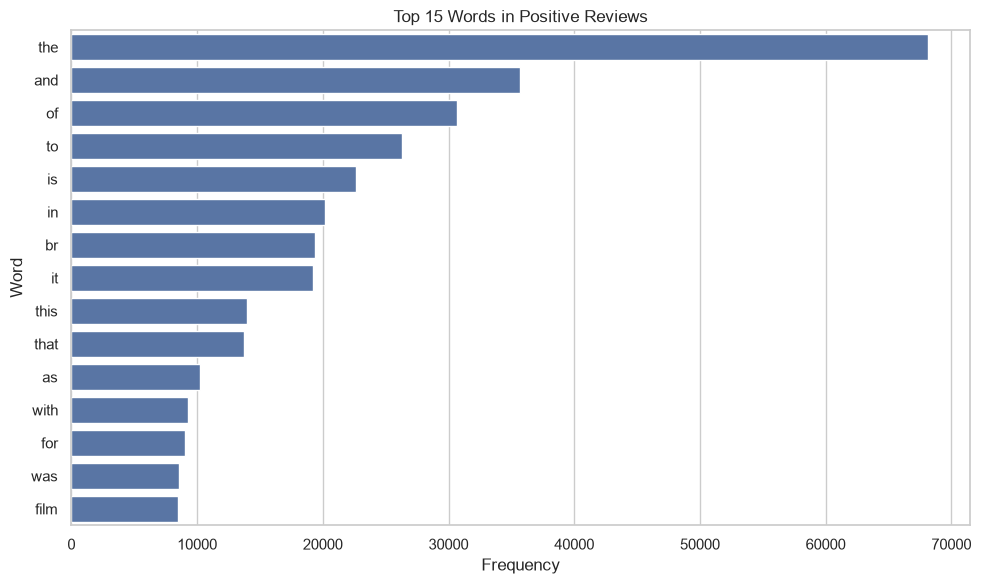

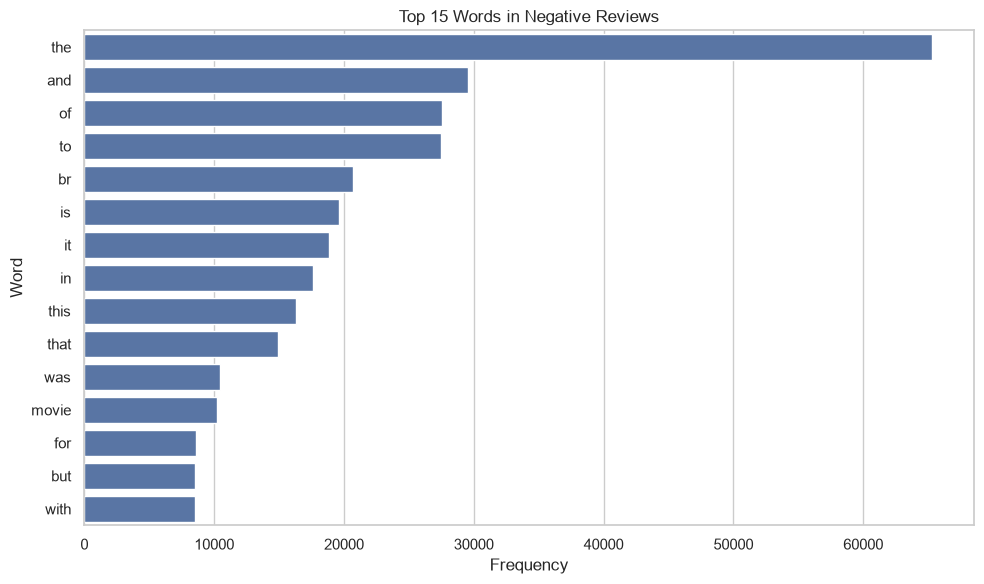

In [16]:
#Step 9 — Visualize the most frequent words

# Extract the most common words
positive_top = Counter(positive_words).most_common(15)
negative_top = Counter(negative_words).most_common(15)

positive_freq = pd.DataFrame(
    positive_top, columns=["Word", "Frequency"]
)
negative_freq = pd.DataFrame(
    negative_top, columns=["Word", "Frequency"]
)

# Positive reviews
plt.figure(figsize=(10, 6))
sns.barplot(
    data=positive_freq,
    x="Frequency",
    y="Word"
)
plt.title("Top 15 Words in Positive Reviews")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.tight_layout()
plt.show()

# Negative reviews
plt.figure(figsize=(10, 6))
sns.barplot(
    data=negative_freq,
    x="Frequency",
    y="Word"
)
plt.title("Top 15 Words in Negative Reviews")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.tight_layout()
plt.show()


Sentiment Percentage Within Each Review-Length Group:


sentiment,negative,positive
length_group,,
0–50 words,44.57,55.43
51–100 words,45.86,54.14
101–200 words,51.13,48.87
201–500 words,50.97,49.03
500+ words,45.99,54.01


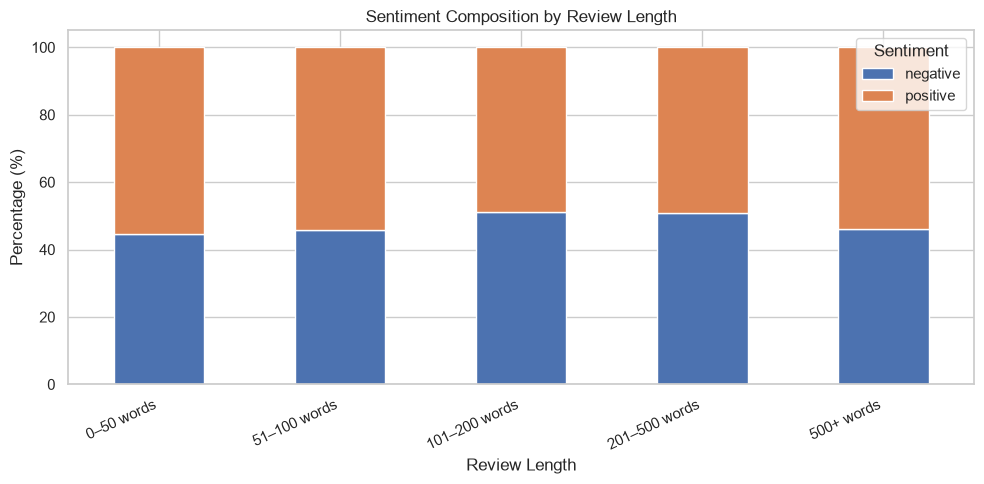

In [17]:
#Step 10 — Compare sentiment with review length

# Create review-length ranges for comparison
eda_df["length_group"] = pd.cut(
    eda_df["word_count"],
    bins=[-1, 50, 100, 200, 500, np.inf],
    labels=[
        "0–50 words",
        "51–100 words",
        "101–200 words",
        "201–500 words",
        "500+ words"
    ]
)

# Calculate sentiment percentages within each length group
length_sentiment = pd.crosstab(
    eda_df["length_group"],
    eda_df["sentiment"],
    normalize="index"
).mul(100).round(2)

print("Sentiment Percentage Within Each Review-Length Group:")
display(length_sentiment)

# Plot sentiment proportions
length_sentiment.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5)
)
plt.title("Sentiment Composition by Review Length")
plt.xlabel("Review Length")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=25, ha="right")
plt.legend(title="Sentiment")
plt.tight_layout()
plt.show()


In [18]:
#Step 11 — Final EDA summary

# Build a final dataset summary
total_reviews = len(df)
valid_sentiments = df["sentiment"].dropna().astype(str).str.lower()

summary = {
    "Total rows": total_reviews,
    "Total columns": len(df.columns),
    "Missing values (all columns)": int(df.isnull().sum().sum()),
    "Duplicate rows": int(df.duplicated().sum()),
    "Empty reviews": int(
        df["review"].fillna("").astype(str).str.strip().eq("").sum()
    ),
    "Unique sentiment labels": int(df["sentiment"].nunique()),
    "Average review word count": round(
        eda_df["word_count"].mean(), 2
    ),
    "Median review word count": round(
        eda_df["word_count"].median(), 2
    )
}

print("FINAL EDA SUMMARY")
print("=" * 40)

for metric, value in summary.items():
    print(f"{metric}: {value}")

print("\nSentiment Counts:")
display(df["sentiment"].value_counts(dropna=False).to_frame("Count"))

print("\nSentiment Percentages:")
display(
    (df["sentiment"].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
    .to_frame("Percentage (%)")
)


FINAL EDA SUMMARY
Total rows: 50000
Total columns: 2
Missing values (all columns): 0
Duplicate rows: 418
Empty reviews: 0
Unique sentiment labels: 2
Average review word count: 231.16
Median review word count: 173.0

Sentiment Counts:


,Count
sentiment,
positive,25000
negative,25000



Sentiment Percentages:


,Percentage (%)
sentiment,
positive,50.0
negative,50.0


DATASET PREPARATION
Usable reviews: 49582

Sentiment distribution:
sentiment
positive    24884
negative    24698
Name: count, dtype: int64[pyarrow]

Training reviews: 39665
Testing reviews: 9917

TRAINING MODEL
Model training completed successfully!

MODEL EVALUATION
Accuracy: 0.8820
Accuracy Percentage: 88.20%
ROC-AUC Score: 0.9514

Classification Report:
                 precision    recall  f1-score   support

Negative Review     0.8858    0.8761    0.8809      4940
Positive Review     0.8784    0.8879    0.8831      4977

       accuracy                         0.8820      9917
      macro avg     0.8821    0.8820    0.8820      9917
   weighted avg     0.8821    0.8820    0.8820      9917

Confusion Matrix:
[[4328  612]
 [ 558 4419]]


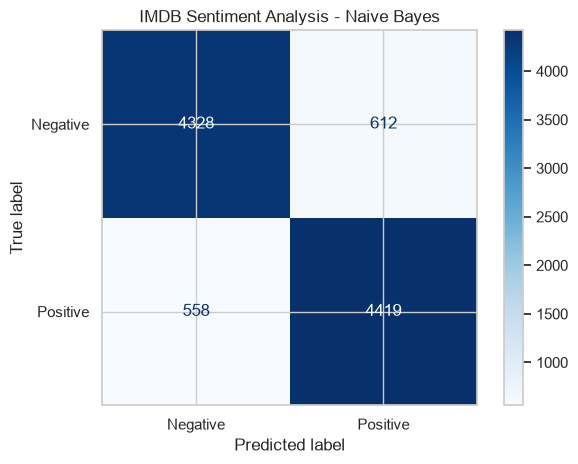

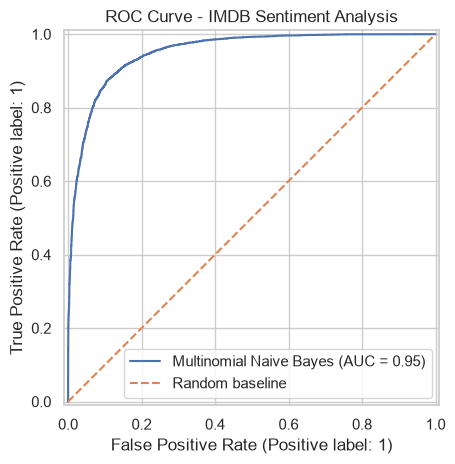


First 10 Test Predictions:


,Review,Actual Sentiment,Predicted Sentiment,Positive Probability
0,My wife and I watched this after DVR'ing it of...,negative,negative,0.0187
1,I was surprised how much I enjoyed this. Sure ...,positive,positive,0.8939
2,Such a delightful movie! Very heart warming. O...,positive,positive,0.9336
3,"""La Lupa Mannara"" aka. ""Werewolf Woman"" of 197...",negative,negative,0.2378
4,First this movie was not that bad.It was enter...,negative,negative,0.3355
5,"""Saturday Afternoon"" is one of Harry Langdon's...",positive,positive,0.9276
6,"Where to begin? <br /><br />#1 Amitabh's son, ...",negative,negative,0.0935
7,Mickey Rourke ( who was once a famous movie st...,negative,negative,0.1888
8,"""Tourist Trap"" is a genuinely spooky low-budge...",positive,positive,0.8467
9,I had the dubious opportunity to view this mov...,negative,negative,0.0426



Predictions for New Reviews:


,Review,Predicted Sentiment,Positive Probability
0,"This movie was fantastic, emotional, and beaut...",positive,0.9481
1,"The movie was boring, poorly written, and a co...",negative,0.0094
2,The film was not good and I did not enjoy it.,negative,0.3833



FINAL PROJECT SUMMARY
Algorithm: Multinomial Naive Bayes
Text Representation: TF-IDF with unigrams and bigrams
Training Samples: 39665
Testing Samples: 9917
Test Accuracy: 88.20%
ROC-AUC Score: 0.9514
Target Classes: [np.str_('negative'), np.str_('positive')]

Sentiment analysis workflow completed!


In [20]:
#NAIVE BAYES :

# STEP 1: IMPORT REQUIRED LIBRARIES
# These libraries help us prepare text, train the model,
# and evaluate its performance.

import re
import html
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    RocCurveDisplay
)


# STEP 2: PREPARE THE DATASET
# We use review as the input and sentiment as the answer
# the model must learn to predict.

data = df[["review", "sentiment"]].copy()

# Standardize labels to lowercase and remove extra spaces.
data["sentiment"] = (
    data["sentiment"].astype("string").str.strip().str.lower()
)

# Remove rows with missing reviews or missing sentiment labels.
data = data.dropna(subset=["review", "sentiment"])

# Convert reviews to strings and remove empty reviews.
data["review"] = data["review"].astype(str)
data = data[data["review"].str.strip().ne("")]

# Keep only the two sentiment classes expected in this project.
data = data[data["sentiment"].isin(["positive", "negative"])]

# Remove exact duplicate review-label records.
# This avoids counting identical records repeatedly.
data = data.drop_duplicates(subset=["review", "sentiment"])

# Reset row numbering after cleaning.
data = data.reset_index(drop=True)

# X contains review text; y contains the correct sentiment labels.
X = data["review"]
y = data["sentiment"]

print("=" * 60)
print("DATASET PREPARATION")
print("=" * 60)
print("Usable reviews:", len(data))
print("\nSentiment distribution:")
print(y.value_counts())


# STEP 3: SPLIT THE DATA INTO TRAINING AND TESTING SETS
# Training data teaches the model.
# Testing data checks how well it predicts unseen reviews.
# Stratification keeps the class proportions similar in both sets.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining reviews:", len(X_train))
print("Testing reviews:", len(X_test))


# STEP 4: CLEAN THE TEXT
# Reviews may contain HTML tags and web links.
# We remove these artifacts while keeping the review's words.
# We do not remove words like "not", because negation matters
# for sentiment (for example, "not good").

def clean_text(text):
    # Decode HTML entities such as &amp;.
    text = html.unescape(text)

    # Remove HTML tags such as <br />.
    text = re.sub(r"<[^>]+>", " ", text)

    # Remove URLs.
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    # Replace repeated whitespace with a single space.
    text = re.sub(r"\s+", " ", text).strip()

    return text


# STEP 5: BUILD THE MACHINE LEARNING PIPELINE
# TF-IDF converts words into numerical features.
# Unigrams are single words; bigrams are two-word phrases.
# Multinomial Naive Bayes learns patterns from those features.
#
# Putting both steps in one pipeline ensures that TF-IDF is
# fitted only on training reviews, helping prevent data leakage.

model = Pipeline(steps=[
    (
        "tfidf",
        TfidfVectorizer(
            preprocessor=clean_text,
            lowercase=True,
            ngram_range=(1, 2),
            max_features=50000,
            min_df=2,
            max_df=0.95,
            sublinear_tf=True
        )
    ),
    (
        "classifier",
        MultinomialNB(alpha=0.5)
    )
])


# STEP 6: TRAIN THE MODEL
# fit() learns vocabulary, TF-IDF values, and sentiment patterns
# from the training reviews.

print("\n" + "=" * 60)
print("TRAINING MODEL")
print("=" * 60)

model.fit(X_train, y_train)

print("Model training completed successfully!")


# STEP 7: MAKE PREDICTIONS
# Predict the sentiment label for each unseen test review.
# predict_proba() estimates the probability of each sentiment.

y_pred = model.predict(X_test)

# Find which probability column corresponds to "positive".
positive_index = list(
    model.named_steps["classifier"].classes_
).index("positive")

y_probability = model.predict_proba(X_test)[:, positive_index]


# STEP 8: EVALUATE MODEL PERFORMANCE
# Accuracy measures the fraction of correct predictions.
# Precision measures how reliable positive predictions are.
# Recall measures how many actual examples are found.
# F1-score balances precision and recall.
# ROC-AUC evaluates how well the model ranks positive reviews
# above negative reviews across classification thresholds.

accuracy = accuracy_score(y_test, y_pred)
auc = roc_auc_score(
    (y_test == "positive").astype(int),
    y_probability
)

print("\n" + "=" * 60)
print("MODEL EVALUATION")
print("=" * 60)

print(f"Accuracy: {accuracy:.4f}")
print(f"Accuracy Percentage: {accuracy * 100:.2f}%")
print(f"ROC-AUC Score: {auc:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=["negative", "positive"],
    target_names=["Negative Review", "Positive Review"],
    digits=4,
    zero_division=0
))


# STEP 9: DISPLAY THE CONFUSION MATRIX
# Rows represent actual sentiment.
# Columns represent predicted sentiment.
# The diagonal cells show correct predictions.

labels = ["negative", "positive"]

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels
)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("IMDB Sentiment Analysis - Naive Bayes")
plt.tight_layout()
plt.show()


# STEP 10: PLOT THE ROC CURVE
# The curve shows the trade-off between true-positive rate
# and false-positive rate at different probability thresholds.

RocCurveDisplay.from_predictions(
    (y_test == "positive").astype(int),
    y_probability,
    name="Multinomial Naive Bayes"
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
plt.title("ROC Curve - IMDB Sentiment Analysis")
plt.legend()
plt.tight_layout()
plt.show()


# STEP 11: COMPARE ACTUAL AND PREDICTED SENTIMENTS
# Display a small sample to inspect individual predictions.
# Probability is the model's estimated probability of positivity.

results = pd.DataFrame({
    "Review": X_test.reset_index(drop=True),
    "Actual Sentiment": y_test.reset_index(drop=True),
    "Predicted Sentiment": y_pred,
    "Positive Probability": np.round(y_probability, 4)
})

print("\nFirst 10 Test Predictions:")
display(results.head(10))


# STEP 12: TEST THE MODEL ON YOUR OWN REVIEWS
# These examples were not used to train the model.
# Change the text to test other movie reviews.

new_reviews = [
    "This movie was fantastic, emotional, and beautifully acted.",
    "The movie was boring, poorly written, and a complete waste of time.",
    "The film was not good and I did not enjoy it."
]

new_predictions = model.predict(new_reviews)
new_probabilities = model.predict_proba(new_reviews)[:, positive_index]

custom_results = pd.DataFrame({
    "Review": new_reviews,
    "Predicted Sentiment": new_predictions,
    "Positive Probability": np.round(new_probabilities, 4)
})

print("\nPredictions for New Reviews:")
display(custom_results)


# STEP 13: FINAL SUMMARY
# Summarize the dataset split and overall test performance.

print("\n" + "=" * 60)
print("FINAL PROJECT SUMMARY")
print("=" * 60)

print("Algorithm: Multinomial Naive Bayes")
print("Text Representation: TF-IDF with unigrams and bigrams")
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))
print(f"Test Accuracy: {accuracy * 100:.2f}%")
print(f"ROC-AUC Score: {auc:.4f}")
print("Target Classes:", list(model.named_steps["classifier"].classes_))
print("\nSentiment analysis workflow completed!")
#TF-IDF: Converts text into numerical features while reducing the influence of words that appear in many reviews.
#Unigrams and bigrams: Captures individual words and short phrases, such as "not good".
#Pipeline: Fits text preprocessing and the classifier using the training data, rather than learning the vocabulary from the test set.
#Stratified split: Keeps positive and negative class proportions similar in the training and testing sets.
#Multiple evaluation metrics: Accuracy alone is not enough, so we also calculate precision, recall, F1-score, and ROC-AUC.
#New-review testing: Lets you experiment with your own movie reviews after training.